In [1]:
import sys
from pathlib import Path

CODE_ROOT = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline")
for folder in ["", "scripts", "pre_processing", "feature_extraction", "post_processing"]:
    if str(CODE_ROOT / folder) not in sys.path:
        sys.path.insert(0, str(CODE_ROOT / folder))

import json
import os
import re
import numpy as np
import yaml
from pathlib import Path
import pandas as pd

import gzip
import struct
import math

import SimpleITK as sitk
import time

from scipy import ndimage
import matplotlib.pyplot as plt

from scripts import *
from visualize import *


In [2]:
import yaml
config_path = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/config_files/setup.yaml")

with open(config_path, "r") as f:
    config = yaml.safe_load(f)

config

{'DATA_ROOT': '/Users/kamleshranabhat/Desktop/radiomics/dataset',
 'IMAGES_DIR': '/Users/kamleshranabhat/Desktop/radiomics/dataset/imagesTr',
 'LABELS_DIR': '/Users/kamleshranabhat/Desktop/radiomics/dataset/labelTr',
 'PROJECT_ROOT': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline',
 'CODEBASE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline',
 'OUTPUT_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs',
 'MASK_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/masks',
 'FEATURE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/features',
 'TABLE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/tables',
 'FIGURE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures',
 'REGISTRATION_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/registration',
 'BIAS_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/bias_correction',
 'REP

In [3]:
rows = []
for folder in (Path(config["IMAGES_DIR"]), Path(config["LABELS_DIR"])):
    for path in sorted(folder.glob("*.nii.gz")):
        rows.append({"folder": folder.name, "file": path.name, "MB": round(path.stat().st_size / 1e6, 1)})
inventory = pd.DataFrame(rows)
print("%d files, %.1f MB in total" % (len(inventory), inventory["MB"].sum()))
display(inventory.groupby("folder").agg(files=("file", "size"), total_MB=("MB", "sum")))
display(inventory.head(6))

25 files, 737.2 MB in total


,files,total_MB
folder,,
imagesTr,20,736.1
labelTr,5,1.1


,folder,file,MB
0,imagesTr,BreastMRI002_0000.nii.gz,37.9
1,imagesTr,BreastMRI002_0001.nii.gz,37.8
2,imagesTr,BreastMRI002_0002.nii.gz,36.5
3,imagesTr,BreastMRI002_0003.nii.gz,37.8
4,imagesTr,BreastMRI006_0000.nii.gz,38.6
5,imagesTr,BreastMRI006_0001.nii.gz,36.8


In [4]:
path = "/Users/kamleshranabhat/Desktop/radiomics/dataset/imagesTr/BreastMRI002_0000.nii.gz"

header, array = read_nifti(path)

image = sitk.ReadImage(path)
sitk_array = sitk.GetArrayFromImage(image)

print("\nSimpleITK")
print("size (x,y,z) =", image.GetSize())
print("spacing      =", np.round(image.GetSpacing(), 4))
print("pixel type   =", image.GetPixelIDTypeAsString())

print(
    "\nvoxel data identical to SimpleITK:",
    np.array_equal(array, sitk_array)
)


SimpleITK
size (x,y,z) = (512, 512, 142)
spacing      = [0.5859 0.5859 1.3   ]
pixel type   = 16-bit signed integer

voxel data identical to SimpleITK: True


In [5]:
rows = []
study_ids = []
for case in list_case():
        label_header = read_nifti_header(label_path(case))
        label_geometry = nifti_geometry_lps(label_header)
        for channel in range(int(config["N_CHANNELS"])):
            h = read_nifti_header(image_path(case, channel))
            g = nifti_geometry_lps(h)
            rows.append({
                "case": case, "channel": channel,
                "matrix_xyz": h["dim"][:3],
                "spacing_mm": tuple(round(v, 3) for v in h["pixdim"][:3]),
                "dtype": config["NIFTI_DTYPES"][h["datatype"]],
                "scaling": (h["scl_slope"], h["scl_inter"]),
                "same_grid_as_label": (h["dim"][:3] == label_header["dim"][:3]
                                    and np.allclose(g["origin"], label_geometry["origin"], atol=1e-3)
                                    and np.allclose(g["direction"], label_geometry["direction"], atol=1e-5)
                                    and np.allclose(g["spacing"], label_geometry["spacing"], atol=1e-5)),
        })
geometry_table = pd.DataFrame(rows)
display(geometry_table[geometry_table.channel == 0].drop(columns="channel"))
print("all 4 channels of a case share one grid:",
      all(g[["matrix_xyz", "spacing_mm"]].astype(str).drop_duplicates().shape[0] == 1
          for _, g in geometry_table.groupby("case")))
print("every image is on exactly the grid of its label:", bool(geometry_table["same_grid_as_label"].all()))
print("intensity scaling always identity:", set(geometry_table["scaling"]) == {(1.0, 0.0)})
geometry_table.to_csv(Path(config["TABLE_DIR"]) / "geometry_audit.csv", index=False)
    

,case,matrix_xyz,spacing_mm,dtype,scaling,same_grid_as_label
0,BreastMRI002,"(512, 512, 142)","(0.586, 0.586, 1.3)",<i2,"(1.0, 0.0)",True
4,BreastMRI006,"(512, 512, 148)","(0.684, 0.684, 1.0)",<i2,"(1.0, 0.0)",True
8,BreastMRI018,"(448, 448, 208)","(0.67, 0.67, 1.0)",<u2,"(1.0, 0.0)",True
12,BreastMRI021,"(512, 512, 176)","(0.742, 0.742, 1.0)",<i2,"(1.0, 0.0)",True
16,BreastMRI023,"(448, 448, 192)","(0.893, 0.893, 1.0)",<u2,"(1.0, 0.0)",True


all 4 channels of a case share one grid: True
every image is on exactly the grid of its label: True
intensity scaling always identity: True


In [6]:
rows = []
label_arrays = {}
study_ids = []

for case in list_case():
        header, label = read_nifti(label_path(case))

        mask = label > 0
        label_arrays[case] = mask
        
        voxel_mm3 = float(np.prod(header["pixdim"][:3]))

        components, n_components = ndimage.label(mask)

        sizes = np.bincount(components.ravel())[1:]
        sizes_sorted = np.sort(sizes)[::-1]

        means = []

        for channel in range(int(config["N_CHANNELS"])):
            _, img = read_nifti(image_path(case, channel))
            means.append(round(float(img[mask].mean()), 1))

        rows.append({
            "case": case,
            "label_values": sorted(np.unique(label).tolist()),
            "n_components": n_components,
            "largest_2": sizes_sorted[:2].tolist(),
            "3rd_largest": int(sizes_sorted[2]) if n_components > 2 else 0,
            "n_below_1000_vox": int((sizes < int(config["MIN_COMPONENT_VOXELS"])).sum()),
            "volume_cm3": round(mask.sum() * voxel_mm3 / 1000, 1),
            "mean_in_label_ch0..3": means,
        })

label_audit = pd.DataFrame(rows)

display(label_audit)

label_audit.to_csv(
    Path(config["TABLE_DIR"]) / "label_audit.csv",
    index=False
)

,case,label_values,n_components,largest_2,3rd_largest,n_below_1000_vox,volume_cm3,mean_in_label_ch0..3
0,BreastMRI002,"[0, 1]",103,"[530794, 529195]",1215,100,476.9,"[1048.0, 997.3, 961.2, 1027.8]"
1,BreastMRI006,"[0, 1]",113,"[677318, 511147]",1267,110,560.0,"[1897.5, 1787.6, 2303.7, 2154.7]"
2,BreastMRI018,"[0, 1]",175,"[165028, 148049]",601,173,146.1,"[178.9, 165.1, 153.7, 136.4]"
3,BreastMRI021,"[0, 1]",1608,"[241624, 235212]",1830,1604,275.4,"[1258.2, 1178.6, 1215.8, 1308.0]"
4,BreastMRI023,"[0, 1]",213,"[145287, 76792]",5038,208,201.4,"[138.3, 155.7, 178.4, 192.5]"


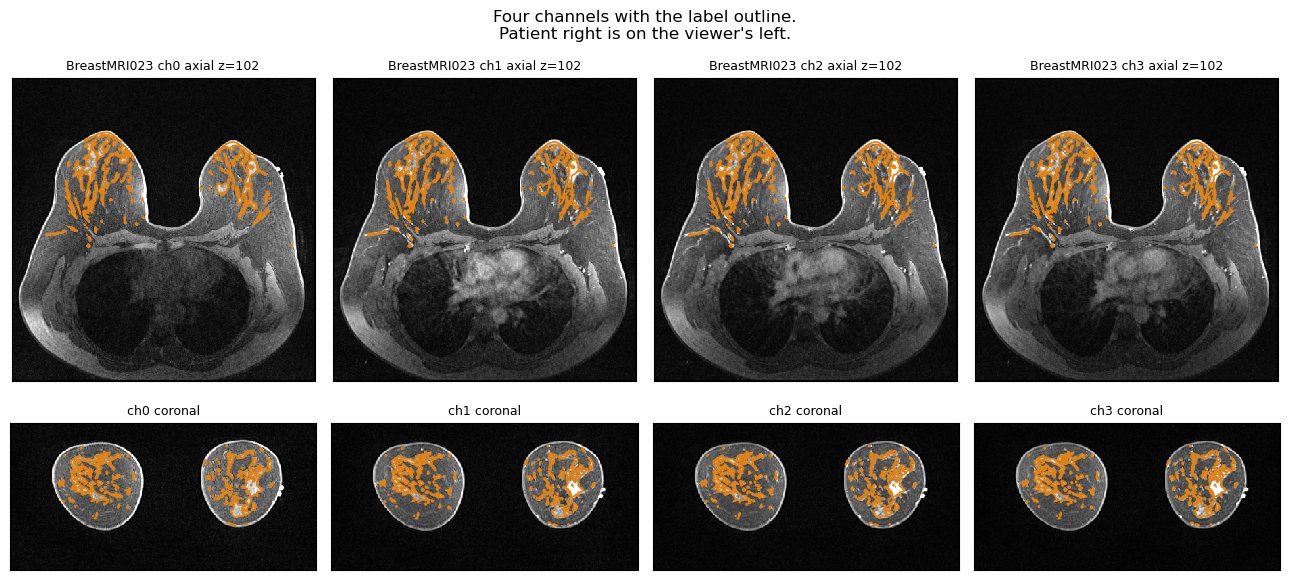

In [7]:
case = "BreastMRI023"
reference_image = load_image(image_path(case, 0))
sp = spacing_zyx(reference_image)
mask = label_arrays[case]
z_index = largest_slice_index(mask, axis=0)

fig, axes = plt.subplots(2, 4, figsize=(13, 6.6))
for channel in range(int(config["N_CHANNELS"])):
    arr = array_from_image(load_image(image_path(case, channel)))
    show_image_with_mask(axes[0, channel], arr, mask, sp, axis=0, index=z_index,
                         title=f"{case} ch{channel} axial z={z_index}")
    show_image_with_mask(axes[1, channel], arr, mask, sp, axis=1,
                         title=f"ch{channel} coronal")
fig.suptitle("Four channels with the label outline.\nPatient right is on the viewer's left.", y=0.99)
fig.tight_layout()
fig.savefig(Path(config["FIGURE_DIR"]) / "channels_with_label.png", dpi=110)
plt.show()

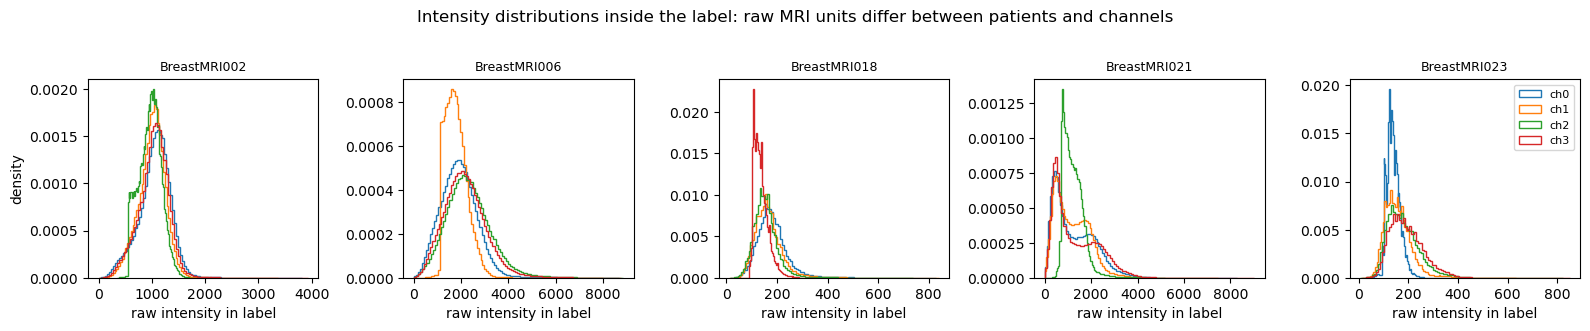

In [8]:
fig, axes = plt.subplots(1, len(list_case()), figsize=(16, 3.2), sharey=False)
for ax, case in zip(axes, list_case()):
    mask = label_arrays[case]
    for channel in range(int(config["N_CHANNELS"])):
        _, img = read_nifti(image_path(case, channel))
        values = img[mask].astype(float)
        ax.hist(values, bins=100, histtype="step", density=True, label=f"ch{channel}")
    ax.set_title(case, fontsize=9)
    ax.set_xlabel("raw intensity in label")
axes[0].set_ylabel("density")
axes[-1].legend(fontsize=8)
fig.suptitle("Intensity distributions inside the label: raw MRI units differ between patients and channels", y=1.02)
fig.tight_layout()
fig.savefig(Path(config["FIGURE_DIR"]) / "intensity_histograms.png", dpi=110, bbox_inches="tight")
plt.show()